# 03 — Dependence on viewing angle

**Feeds:** paper §5, Fig. 2. The isotropic ensemble draws cos ι uniformly, so the efficiency in each cos ι bin is the
efficiency of a population fixed at that angle.

In [1]:
# ---------------------------------------------------------------- settings
SNAPSHOT = "latest"      # "latest" | time stamp or prefix | "newest" | path/to/snapshot.zip | "live"
SAVE_FIGURES = False     # write PDF+PNG of each figure to figures/03/
# ---------------------------------------------------------------------------
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "knrates").is_dir())
sys.path.insert(0, str(ROOT))
for _m in [m for m in list(sys.modules) if m.split(".")[0] == "knrates"]:
    del sys.modules[_m]   # always import the repository copy (a kernel may predate a git pull)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from knrates import notebook as NB, figures as F, analysis as A, plotting as P, literature as L
from knrates.stats import summarize_runs

ctx = NB.setup(SNAPSHOT, save_figures=SAVE_FIGURES, fig_dir="figures/03")
runs, lim, M = ctx.runs, ctx.lim, ctx.models
FIX, ISO = "Bu2026Fixed", "Bu2026Vary"

knrates_results_latest.zip (created 20261111T024800Z, git d7af6653)
models: Bu2026Fixed, Bu2026Vary


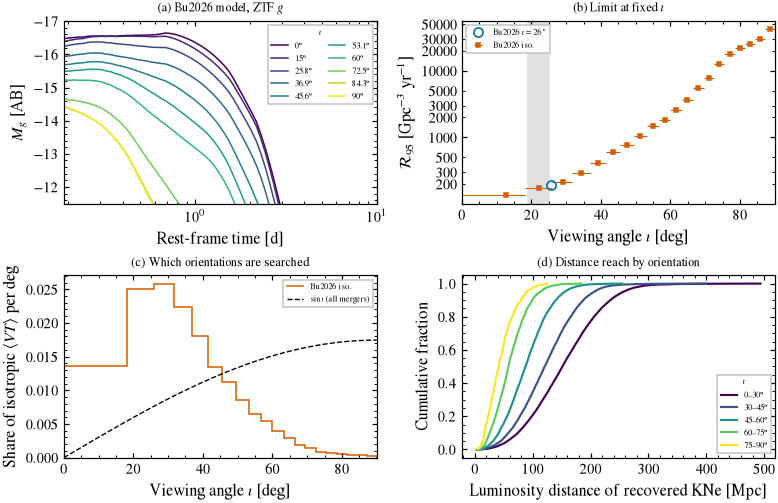

In [2]:
SHOW_LITERATURE = ["mooley2022_gw170817_viewing_angle"]   # options: L.keys("other")
fig = F.viewing_angle(ctx.src, runs, lim, ctx.snap.get("models_lightcurves"), SHOW_LITERATURE)
ctx.save(fig, "viewing_angle"); plt.show()

In [3]:
inc = A.inclination_efficiency(ctx.src, runs, ISO, n_bins=20).sort_values("iota_deg_lo")
display(inc[["iota_deg_lo", "iota_deg_hi", "n_detected", "efficiency", "vt", "r95"]].round(5))
s = ctx.src[ctx.src.model == ISO]
cross = float(np.interp(lim.loc[ISO, "vt_gpc3_yr"], inc.vt[::-1], inc.iota_deg_center[::-1]))
xc = A.inclination_crosscheck(inc, lim, ISO, FIX)
NB.finding(f"⟨VT⟩ falls {inc.vt.iloc[0] / inc.vt.iloc[-1]:.0f}× from the first to the last bin. The isotropic average equals "
           f"the fixed-angle value at ι ≈ {cross:.0f}°. Angles above 45° are {100 * np.cos(np.pi / 4):.0f}% of injections but "
           f"{100 * (s.inclination_rad > np.pi / 4).mean():.0f}% of recoveries.")
NB.finding(f"Check: the isotropic ensemble interpolated to 25.8° reproduces the independent fixed-angle ensemble to "
           f"{100 * abs(xc['rel_diff']):.2f}%.")

,iota_deg_lo,iota_deg_hi,n_detected,efficiency,vt,r95
19,0,18.19,13294,0.00266,0.02225,134.6
18,18.19,25.84,10328,0.00207,0.01729,173.3
17,25.84,31.79,8272,0.00165,0.01385,216.4
16,31.79,36.87,6121,0.00122,0.01024,292.4
15,36.87,41.41,4424,0.00088,0.0074,404.6
14,41.41,45.57,3026,0.00061,0.00506,591.5
13,45.57,49.46,2347,0.00047,0.00393,762.6
12,49.46,53.13,1705,0.00034,0.00285,1050
11,53.13,56.63,1220,0.00024,0.00204,1467
10,56.63,60,977,0.0002,0.00164,1832


> **Result.** ⟨VT⟩ falls 309× from the first to the last bin. The isotropic average equals the fixed-angle value at ι ≈ 45°. Angles above 45° are 71% of injections but 16% of recoveries.

> **Result.** Check: the isotropic ensemble interpolated to 25.8° reproduces the independent fixed-angle ensemble to 0.03%.